# Effectiveness of thrombolysis in early (4hr) arrivals of mild stroke, by individual NIHSS (1, 2, 3, 4, 5) - good outcome: Target trial emulation

This notebook repeats the NIHSS 1-5 target trial emulation, but reports results **separately for each NIHSS score (1, 2, 3, 4 and 5)**, and brings everything together in a single summary table.

**Good outcome = discharged mRS 0-2, or discharge mRS as good as pre-stroke mRS**

## Selection criteria

* Arrival within 4 hours of known stroke onset time
* No thrombectomy
* Stroke type = infarction
* No recorded use of perfusion imaging
* Stroke severity 1-5 (analysed individually)

## Method

* Selection, outcome definition and matching are identical to the grouped NIHSS 1-5 notebook. Each thrombolysed patient is exactly matched to one untreated patient on prior disability, stroke severity, age, AF anticoagulant and any AF diagnosis (controls sampled with replacement, but each untreated patient can be used as a control at most k = 3 times across all treatment-time groups; same random seeds).
* Because stroke severity is an exact-matching feature, every matched pair sits within a single NIHSS score. The matched pairs are therefore the *same pairs* as in the grouped notebook, simply split by NIHSS. The "NIHSS 1-5" rows reproduce the grouped notebook results as a check.
* Results are given for each onset-to-thrombolysis window (<180, 180-270, 270-360 min) and for all thrombolysed patients combined (≤360 min).

## Statistics

* Good outcome proportions are shown with 95% Wilson score confidence intervals.
* Difference = treated minus control (percentage points), with 95% CI from the paired differences.
* Details of how the confidence intervals are calculated are given below the summary table.
* P values are from McNemar's test, which respects the matched-pair design (exact binomial version used when there are fewer than 25 discordant pairs). Note the grouped notebook used an independent-samples t-test for its headline results, so P values for the pooled NIHSS 1-5 rows will differ slightly from that notebook.
* P values are **not adjusted for multiple comparisons**. Splitting by NIHSS and time window gives many comparisons with smaller samples, so individual rows should be interpreted with caution.

## Load modules

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Disable warnings for cleaner output
import warnings
warnings.filterwarnings("ignore")

## Define settings

In [2]:
prefix = "mild_stroke_by_nihss_1_to_5_early_arrival_good_outcome_target_trial"
DATA_PATH = "../data/sam3/cleaned_data_anon_teams.csv"
OUTPUT_DIR = "./output"
MRS_TARGET = 2
NIHSS_VALUES = [1, 2, 3, 4, 5]
os.makedirs(OUTPUT_DIR, exist_ok=True)

## Load and filter data

Identical to the grouped NIHSS 1-5 notebook.

In [3]:
data = pd.read_csv(DATA_PATH, low_memory=False)

print(f"Initial data shape: {data.shape}")

# Remove rows with missing discharge disability
data = data.dropna(subset=["discharge_disability"])

# Keep only infarction cases
data = data[data["infarction"] == 1]

# Keep only onset to arrival < 240 mins
data = data[data["onset_to_arrival_time"] < 240]

# Keep only perfusion_imaging_used == 0
data = data[data["perfusion_imaging_used"] == 0]

# Exclude patients who received thrombectomy
data = data[data["thrombectomy"] == 0]

# Limit to stroke severity 1 - 5
data = data[(data["stroke_severity"] >= 1) & (data["stroke_severity"] <= 5)]

# Keep only teams with at least 10 onset_to_thrombolysis_time
team_counts = data.groupby("stroke_team")["onset_to_thrombolysis_time"].count()
valid_teams = team_counts[team_counts >= 10].index
data = data[data["stroke_team"].isin(valid_teams)]

# Missing treatment times -> sentinel
data["onset_to_thrombolysis_time"] = data["onset_to_thrombolysis_time"].fillna(99999)

# Exclude late thrombolysis (> 360) unless sentinel
data = data[
    (data["onset_to_thrombolysis_time"] <= 360)
    | (data["onset_to_thrombolysis_time"] == 99999)
]

# Add outcome variable: mRS <= MRS_TARGET or return to pre-stroke mRS
data["outcome_target"] = (
    (data["discharge_disability"] <= MRS_TARGET)
    | (data["discharge_disability"] <= data["prior_disability"])
).astype(int)

print(f"Final data shape: {data.shape}")

# Treatment counts
num_thrombolysis = (data["onset_to_thrombolysis_time"] != 99999).sum()
print(f"Number of patients with thrombolysis: {num_thrombolysis}")

Initial data shape: (452863, 73)
Final data shape: (58389, 74)
Number of patients with thrombolysis: 13380


Add time labels.

In [4]:
control_group_name = "No thrombolysis"
ALL_TREATED = "All (≤360 min)"

data.loc[data["onset_to_thrombolysis_time"] <= 180, "treatment_group"] = "<180 min"
data.loc[(data["onset_to_thrombolysis_time"] > 180) & (data["onset_to_thrombolysis_time"] <= 270), "treatment_group"] = "180-270 min"
data.loc[(data["onset_to_thrombolysis_time"] > 270) & (data["onset_to_thrombolysis_time"] <= 360), "treatment_group"] = "270-360 min"
data.loc[data["onset_to_thrombolysis_time"] == 99999, "treatment_group"] = control_group_name

MATCHING_FEATURES = [
    'prior_disability',
    'stroke_severity',
    'age',
    'afib_anticoagulant',
    'any_afib_diagnosis'
]

# Numbers available before matching, by NIHSS and treatment group
pd.crosstab(data["stroke_severity"], data["treatment_group"], margins=True)

treatment_group,180-270 min,270-360 min,<180 min,No thrombolysis,All
stroke_severity,,,,,
1.0,341,34,347,10280,11002
2.0,732,90,925,12398,14145
3.0,1162,98,1525,10071,12856
4.0,1601,131,2220,7016,10968
5.0,1678,123,2373,5244,9418
All,5514,476,7390,45009,58389


## Matching

Same matching as the grouped notebook (same order of treated patients and same random seeds), except that each untreated patient can be used as a control at most `MAX_CONTROL_USES` (k, initially 3) times across all treatment-time groups. Once a control reaches the limit it is no longer available; a treated patient whose matching controls are all used up is left unmatched. Because the limit is shared across groups, matching order matters: groups are matched in the order 180-270, 270-360, <180 min, and patients in data order within each group. The untreated patients are pre-grouped by the matching features, which gives identical matches but runs much faster.

In [5]:
# Maximum number of times any one untreated patient can be used as a control
# (across all treatment-time groups). Set to None for unlimited re-use.
MAX_CONTROL_USES = 3

treatment_groups = sorted(
    group for group in data["treatment_group"].dropna().unique()
    if group != control_group_name
)

untreated_group = data[data["treatment_group"] == control_group_name]

# Row positions of untreated patients for each combination of matching features
# (order within each combination is preserved, so sampling matches the grouped notebook)
untreated_lookup = untreated_group.groupby(MATCHING_FEATURES, sort=False).indices

# Number of times each untreated patient (by row position) has been used as a control
control_use_count = np.zeros(len(untreated_group), dtype=int)
max_uses = np.inf if MAX_CONTROL_USES is None else MAX_CONTROL_USES

matched_samples = {}
unmatched_rows = []

for group_name in treatment_groups:
    treated_group = data[data["treatment_group"] == group_name]

    if treated_group.empty or untreated_group.empty:
        continue

    treated_positions = []
    untreated_positions = []
    count = 0
    n_exhausted = 0

    for key in treated_group[MATCHING_FEATURES].itertuples(index=False, name=None):
        count += 1
        candidates = untreated_lookup.get(key)

        if candidates is None or len(candidates) == 0:
            reason = "no exact match"
        else:
            # Only controls that have not yet reached the re-use limit
            available = candidates[control_use_count[candidates] < max_uses]
            if len(available) > 0:
                chosen = pd.Series(available).sample(n=1, random_state=42 + count).iloc[0]
                control_use_count[chosen] += 1
                treated_positions.append(count - 1)
                untreated_positions.append(chosen)
                continue
            reason = f"all matching controls used {MAX_CONTROL_USES} times"
            n_exhausted += 1

        unmatched_rows.append({
            "treatment_group": group_name,
            "stroke_severity": key[MATCHING_FEATURES.index("stroke_severity")],
            "reason": reason,
        })

    matched_samples[group_name] = {
        "treated": treated_group.iloc[treated_positions].reset_index(drop=True),
        "untreated": untreated_group.iloc[untreated_positions].reset_index(drop=True),
        "n_treated_total": len(treated_group),
    }

    print(f"{group_name}: matched {len(treated_positions)} of {len(treated_group)} "
          f"({100 * len(treated_positions) / len(treated_group):.2f}%); "
          f"{n_exhausted} unmatched because matching controls reached the re-use limit")

# Summary of control re-use
used = control_use_count[control_use_count > 0]
print(f"\nControl re-use limit (k): {MAX_CONTROL_USES}")
print(f"Distinct controls used: {len(used)}; total control slots: {used.sum()}")
print("Number of controls by times used:")
print(pd.Series(used).value_counts().sort_index().rename_axis("times used").to_string())

180-270 min: matched 5512 of 5514 (99.96%); 0 unmatched because matching controls reached the re-use limit
270-360 min: matched 475 of 476 (99.79%); 0 unmatched because matching controls reached the re-use limit
<180 min: matched 7362 of 7390 (99.62%); 16 unmatched because matching controls reached the re-use limit

Control re-use limit (k): 3
Distinct controls used: 9749; total control slots: 13349
Number of controls by times used:
times used
1    7022
2    1854
3     873


Put all matched pairs in one table (one row per pair).

In [6]:
pairs = []
for group_name, samples in matched_samples.items():
    treated = samples["treated"]
    untreated = samples["untreated"]
    pairs.append(pd.DataFrame({
        "treatment_group": group_name,
        "stroke_severity": treated["stroke_severity"].astype(int),
        "treated_outcome": treated["outcome_target"].astype(int),
        "untreated_outcome": untreated["outcome_target"].astype(int),
    }))
pairs = pd.concat(pairs, ignore_index=True)

# Number of treated patients before matching (for percent matched)
treated_all = data[data["treatment_group"] != control_group_name]
print(f"Total matched pairs: {len(pairs)}")

Total matched pairs: 13349


## Analysis by individual NIHSS

In [7]:
def wilson_ci(values, alpha=0.05):
    """Proportion and Wilson score CI for a 0/1 outcome."""
    values = np.asarray(values, dtype=float)
    n = len(values)
    if n == 0:
        return np.nan, np.nan, np.nan
    p = values.mean()
    z = stats.norm.ppf(1 - alpha / 2)
    denominator = 1 + z ** 2 / n
    centre = (p + z ** 2 / (2 * n)) / denominator
    half_width = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / denominator
    return p, centre - half_width, centre + half_width


def paired_difference_ci(treated, untreated, alpha=0.05):
    """Mean of the per-pair differences (treated - untreated) and its CI:
    mean +/- t * SD / sqrt(n), where each pair's difference is -1, 0 or +1."""
    differences = np.asarray(treated, dtype=float) - np.asarray(untreated, dtype=float)
    n = len(differences)
    mean = differences.mean()
    half_width = stats.t.ppf(1 - alpha / 2, n - 1) * differences.std(ddof=1) / np.sqrt(n)
    return mean, mean - half_width, mean + half_width


def mcnemar_p(treated, untreated):
    """McNemar test for matched pairs. Exact binomial if < 25 discordant pairs,
    otherwise continuity-corrected chi-square (as in grouped notebook)."""
    treated_only = int(((treated == 1) & (untreated == 0)).sum())
    untreated_only = int(((treated == 0) & (untreated == 1)).sum())
    discordant = treated_only + untreated_only
    if discordant == 0:
        return 1.0, treated_only, untreated_only
    if discordant < 25:
        p = stats.binomtest(treated_only, discordant, 0.5).pvalue
    else:
        p = stats.chi2.sf((abs(treated_only - untreated_only) - 1) ** 2 / discordant, 1)
    return p, treated_only, untreated_only


def analyse(df, nihss_label, group_label, n_treated_total):
    treated = df["treated_outcome"].to_numpy()
    untreated = df["untreated_outcome"].to_numpy()
    n = len(df)

    row = {
        "nihss": nihss_label,
        "treatment_group": group_label,
        "treated_n_before_matching": n_treated_total,
        "matched_n": n,
        "percent_matched": 100 * n / n_treated_total if n_treated_total else np.nan,
    }
    if n < 2:
        return row

    t_mean, t_lo, t_hi = wilson_ci(treated)
    u_mean, u_lo, u_hi = wilson_ci(untreated)
    d_mean, d_lo, d_hi = paired_difference_ci(treated, untreated)
    p_mcn, treated_only, untreated_only = mcnemar_p(treated, untreated)

    row.update({
        "treated_good_outcome": t_mean,
        "treated_ci_lower": t_lo,
        "treated_ci_upper": t_hi,
        "treated_std": treated.std(ddof=1),
        "untreated_good_outcome": u_mean,
        "untreated_ci_lower": u_lo,
        "untreated_ci_upper": u_hi,
        "untreated_std": untreated.std(ddof=1),
        "difference": d_mean,
        "difference_ci_lower": d_lo,
        "difference_ci_upper": d_hi,
        "pairs_treated_only_good": treated_only,
        "pairs_untreated_only_good": untreated_only,
        "p_value_mcnemar": p_mcn,
    })
    return row


group_order = [ALL_TREATED, "<180 min", "180-270 min", "270-360 min"]
nihss_order = [str(n) for n in NIHSS_VALUES] + ["1-5"]

results = []
for nihss_label in nihss_order:
    if nihss_label == "1-5":
        pairs_n = pairs
        treated_n = treated_all
    else:
        pairs_n = pairs[pairs["stroke_severity"] == int(nihss_label)]
        treated_n = treated_all[treated_all["stroke_severity"] == int(nihss_label)]

    for group_label in group_order:
        if group_label == ALL_TREATED:
            df = pairs_n
            n_total = len(treated_n)
        else:
            df = pairs_n[pairs_n["treatment_group"] == group_label]
            n_total = (treated_n["treatment_group"] == group_label).sum()
        results.append(analyse(df, nihss_label, group_label, int(n_total)))

results_df = pd.DataFrame(results)
results_df.to_csv(f"{OUTPUT_DIR}/{prefix}_summary_full.csv", index=False)
results_df.round(4)

,nihss,treatment_group,treated_n_before_matching,matched_n,percent_matched,treated_good_outcome,treated_ci_lower,treated_ci_upper,treated_std,untreated_good_outcome,untreated_ci_lower,untreated_ci_upper,untreated_std,difference,difference_ci_lower,difference_ci_upper,pairs_treated_only_good,pairs_untreated_only_good,p_value_mcnemar
0,1,All (≤360 min),722,722,100.0000,0.8463,0.8181,0.8707,0.3609,0.8490,0.8211,0.8733,0.3583,-0.0028,-0.0405,0.0349,95,97,0.9425
1,1,<180 min,347,347,100.0000,0.8617,0.8214,0.8941,0.3457,0.8703,0.8309,0.9016,0.3364,-0.0086,-0.0616,0.0443,42,45,0.8302
2,1,180-270 min,341,341,100.0000,0.8358,0.7928,0.8713,0.3710,0.8270,0.7832,0.8634,0.3788,0.0088,-0.0475,0.0651,49,46,0.8374
3,1,270-360 min,34,34,100.0000,0.7941,0.6320,0.8965,0.4104,0.8529,0.6987,0.9355,0.3595,-0.0588,-0.2498,0.1321,4,6,0.7539
4,2,All (≤360 min),1747,1745,99.8855,0.8372,0.8192,0.8538,0.3692,0.8287,0.8103,0.8456,0.3769,0.0086,-0.0155,0.0327,238,223,0.5144
5,2,<180 min,925,923,99.7838,0.8418,0.8169,0.8639,0.3651,0.8212,0.7952,0.8446,0.3834,0.0206,-0.0123,0.0534,129,110,0.2443
6,2,180-270 min,732,732,100.0000,0.8361,0.8075,0.8611,0.3705,0.8306,0.8017,0.8560,0.3754,0.0055,-0.0325,0.0434,102,98,0.8320
7,2,270-360 min,90,90,100.0000,0.8000,0.7059,0.8696,0.4022,0.8889,0.8074,0.9385,0.3160,-0.0889,-0.1913,0.0135,7,15,0.1338
8,3,All (≤360 min),2785,2781,99.8564,0.8148,0.7999,0.8288,0.3885,0.7670,0.7509,0.7823,0.4228,0.0478,0.0271,0.0685,500,367,0.0000
9,3,<180 min,1525,1522,99.8033,0.8187,0.7985,0.8372,0.3854,0.7694,0.7476,0.7899,0.4214,0.0493,0.0217,0.0768,268,193,0.0006


## Summary table

Single table of all results. "Treated (n)" is the number of thrombolysed patients before matching, and "Treated matched (%)" is the percentage of them for whom an exactly matched control was found. Good outcome is shown as % (95% CI); difference is treated minus control in percentage points (95% CI). The "1-5" rows are the pooled results, equivalent to the grouped notebook.

In [8]:
def fmt_pct(mean, lower, upper):
    if pd.isna(mean):
        return "-"
    if pd.isna(lower):
        return f"{100 * mean:.1f}"
    return f"{100 * mean:.1f} ({100 * lower:.1f}, {100 * upper:.1f})"


def fmt_p(p):
    if pd.isna(p):
        return "-"
    return "<0.001" if p < 0.001 else f"{p:.3f}"


summary_table = pd.DataFrame({
    "NIHSS": results_df["nihss"],
    "Onset to thrombolysis": results_df["treatment_group"],
    "Treated (n)": results_df["treated_n_before_matching"],
    "Matched pairs (n)": results_df["matched_n"],
    "Treated matched (%)": results_df["percent_matched"].apply(
        lambda v: "-" if pd.isna(v) else f"{v:.1f}"),
    "Treated good outcome, % (95% CI)": [
        fmt_pct(m, l, u) for m, l, u in zip(
            results_df["treated_good_outcome"],
            results_df["treated_ci_lower"],
            results_df["treated_ci_upper"])],
    "Control good outcome, % (95% CI)": [
        fmt_pct(m, l, u) for m, l, u in zip(
            results_df["untreated_good_outcome"],
            results_df["untreated_ci_lower"],
            results_df["untreated_ci_upper"])],
    "Difference, % points (95% CI)": [
        fmt_pct(m, l, u) for m, l, u in zip(
            results_df["difference"],
            results_df["difference_ci_lower"],
            results_df["difference_ci_upper"])],
    "P value (McNemar)": results_df["p_value_mcnemar"].apply(fmt_p),
})

summary_table.to_csv(f"{OUTPUT_DIR}/{prefix}_summary_table.csv", index=False)

pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.width", 250)
display(summary_table.reset_index(drop=True))

,NIHSS,Onset to thrombolysis,Treated (n),Matched pairs (n),Treated matched (%),"Treated good outcome, % (95% CI)","Control good outcome, % (95% CI)","Difference, % points (95% CI)",P value (McNemar)
0,1,All (≤360 min),722,722,100.0,"84.6 (81.8, 87.1)","84.9 (82.1, 87.3)","-0.3 (-4.0, 3.5)",0.942
1,1,<180 min,347,347,100.0,"86.2 (82.1, 89.4)","87.0 (83.1, 90.2)","-0.9 (-6.2, 4.4)",0.830
2,1,180-270 min,341,341,100.0,"83.6 (79.3, 87.1)","82.7 (78.3, 86.3)","0.9 (-4.7, 6.5)",0.837
3,1,270-360 min,34,34,100.0,"79.4 (63.2, 89.7)","85.3 (69.9, 93.6)","-5.9 (-25.0, 13.2)",0.754
4,2,All (≤360 min),1747,1745,99.9,"83.7 (81.9, 85.4)","82.9 (81.0, 84.6)","0.9 (-1.6, 3.3)",0.514
5,2,<180 min,925,923,99.8,"84.2 (81.7, 86.4)","82.1 (79.5, 84.5)","2.1 (-1.2, 5.3)",0.244
6,2,180-270 min,732,732,100.0,"83.6 (80.8, 86.1)","83.1 (80.2, 85.6)","0.5 (-3.2, 4.3)",0.832
7,2,270-360 min,90,90,100.0,"80.0 (70.6, 87.0)","88.9 (80.7, 93.9)","-8.9 (-19.1, 1.4)",0.134
8,3,All (≤360 min),2785,2781,99.9,"81.5 (80.0, 82.9)","76.7 (75.1, 78.2)","4.8 (2.7, 6.9)",<0.001
9,3,<180 min,1525,1522,99.8,"81.9 (79.9, 83.7)","76.9 (74.8, 79.0)","4.9 (2.2, 7.7)",<0.001


### Where the confidence intervals come from

**Treated and control good outcome (95% CI).** These are Wilson score intervals for a proportion, calculated separately for the treated patients and for their matched controls in each row (function `wilson_ci`). With *p* the observed proportion with a good outcome, *n* the number of matched pairs in the row, and *z* = 1.96:

$$\frac{p + \frac{z^2}{2n}}{1 + \frac{z^2}{n}} \;\pm\; \frac{z}{1 + \frac{z^2}{n}} \sqrt{\frac{p(1-p)}{n} + \frac{z^2}{4n^2}}$$

The Wilson interval is preferred to the simple normal-approximation (Wald) interval because it remains accurate with smaller samples and with proportions near 0% or 100%, and it cannot go outside 0-100%. It is not symmetric around the observed proportion. These intervals describe each arm on its own and do not use the pairing.

**Difference (95% CI).** This is calculated from the matched pairs (function `paired_difference_ci`). For each pair the difference in outcome is treated minus control, which is -1, 0 or +1. The interval is the mean of these differences ± *t* × SD / √*n* (t-distribution with *n* - 1 degrees of freedom). Because it uses the pairing, this is the interval that corresponds to the McNemar P value.

**Interpretation notes.**

* Overlap between the treated and control intervals is not a test of the difference; use the difference interval and the McNemar P value.
* Controls are sampled with replacement (each untreated patient used at most k = 3 times), so the same untreated patient can appear in up to three pairs. Neither the intervals nor the P values allow for this, so they may be slightly too narrow / too small.
* Intervals and P values are not adjusted for multiple comparisons.
* These intervals differ slightly from the grouped NIHSS 1-5 notebook, which used t-based intervals for each arm.

## Headline table: all thrombolysed patients (≤360 min) by NIHSS

A shorter view of the same results, with one row per NIHSS score.

In [9]:
headline_table = summary_table[summary_table["Onset to thrombolysis"] == ALL_TREATED]
headline_table = headline_table.drop(columns="Onset to thrombolysis")
headline_table.to_csv(f"{OUTPUT_DIR}/{prefix}_summary_table_all_treated.csv", index=False)
display(headline_table.reset_index(drop=True))

,NIHSS,Treated (n),Matched pairs (n),Treated matched (%),"Treated good outcome, % (95% CI)","Control good outcome, % (95% CI)","Difference, % points (95% CI)",P value (McNemar)
0,1,722,722,100.0,"84.6 (81.8, 87.1)","84.9 (82.1, 87.3)","-0.3 (-4.0, 3.5)",0.942
1,2,1747,1745,99.9,"83.7 (81.9, 85.4)","82.9 (81.0, 84.6)","0.9 (-1.6, 3.3)",0.514
2,3,2785,2781,99.9,"81.5 (80.0, 82.9)","76.7 (75.1, 78.2)","4.8 (2.7, 6.9)",<0.001
3,4,3952,3929,99.4,"76.4 (75.0, 77.7)","69.8 (68.3, 71.2)","6.6 (4.7, 8.5)",<0.001
4,5,4174,4172,100.0,"71.8 (70.5, 73.2)","63.3 (61.9, 64.8)","8.5 (6.6, 10.5)",<0.001
5,1-5,13380,13349,99.8,"77.4 (76.7, 78.1)","71.7 (71.0, 72.5)","5.7 (4.7, 6.7)",<0.001


## Chart: good outcome by treatment time and NIHSS

One panel per onset-to-thrombolysis window (2x2 grid), with NIHSS along the x-axis. Points show the proportion with a good outcome in treated patients and their matched controls; bars are 95% Wilson confidence intervals. The pooled NIHSS 1-5 result is shown at the right of each panel. The numbers above each pair are McNemar P values (bold if < 0.05, unadjusted).

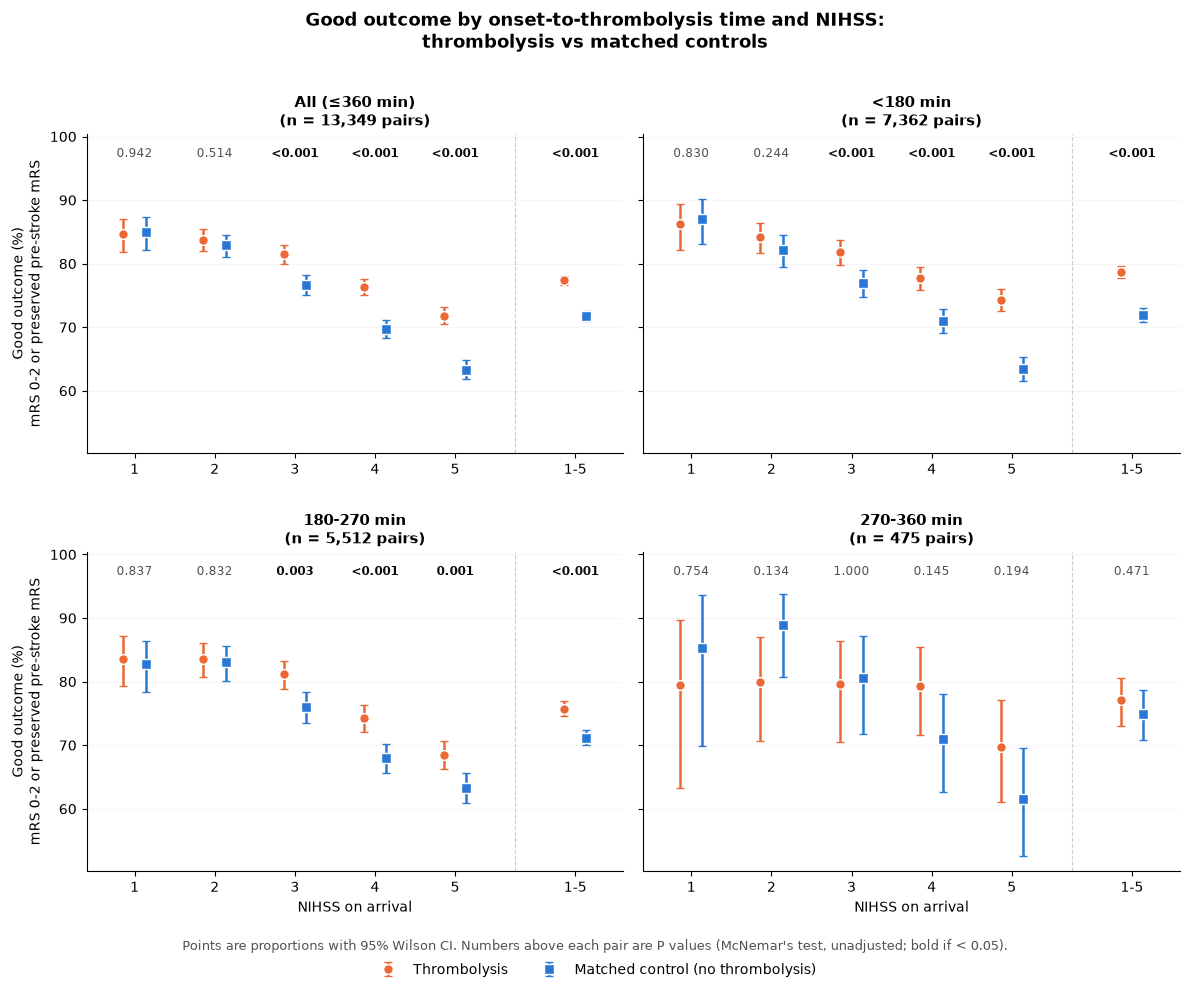

In [10]:
C_TREATED, C_CONTROL = "#eb6834", "#2a78d6"
INK, MUTED = "#0b0b0b", "#52514e"
OFFSET = 0.14

fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharey=True)

# Shared y-range across panels, with headroom for P values
y_low = 100 * np.nanmin(results_df[["treated_ci_lower", "untreated_ci_lower"]].to_numpy())
y_high = 100 * np.nanmax(results_df[["treated_ci_upper", "untreated_ci_upper"]].to_numpy())
y_span = y_high - y_low
y_text = y_high + 0.06 * y_span

x = np.arange(len(nihss_order), dtype=float)
x[-1] += 0.5   # gap before the pooled NIHSS 1-5 result

for ax, group_label in zip(axes.flat, group_order):
    df = (
        results_df[results_df["treatment_group"] == group_label]
        .set_index("nihss")
        .reindex(nihss_order)
    )

    for suffix, offset, colour, marker, label in [
        ("treated", -OFFSET, C_TREATED, "o", "Thrombolysis"),
        ("untreated", OFFSET, C_CONTROL, "s", "Matched control (no thrombolysis)"),
    ]:
        mean = 100 * df[f"{suffix}_good_outcome"].to_numpy(dtype=float)
        lower = 100 * df[f"{suffix}_ci_lower"].to_numpy(dtype=float)
        upper = 100 * df[f"{suffix}_ci_upper"].to_numpy(dtype=float)
        ax.errorbar(
            x + offset, mean, yerr=[mean - lower, upper - mean],
            fmt=marker, color=colour, ecolor=colour, markersize=7,
            markeredgecolor="white", markeredgewidth=1,
            capsize=3, elinewidth=1.8, label=label, zorder=3,
        )

    for xi, p_value in zip(x, df["p_value_mcnemar"]):
        if pd.isna(p_value):
            continue
        p_text = "<0.001" if p_value < 0.001 else f"{p_value:.3f}"
        ax.text(
            xi, y_text, p_text, ha="center", va="bottom", fontsize=8.5,
            fontweight="bold" if p_value < 0.05 else "normal",
            color=INK if p_value < 0.05 else MUTED,
        )

    # Divider between individual NIHSS scores and pooled result
    ax.axvline((x[-2] + x[-1]) / 2, color="0.8", lw=0.8, linestyle="--", zorder=0)

    n_pairs = df.loc["1-5", "matched_n"]
    ax.set_title(f"{group_label}\n(n = {int(n_pairs):,} pairs)", fontweight="bold", fontsize=11)
    ax.set_xticks(x)
    ax.set_xticklabels(nihss_order)
    ax.set_xlim(x[0] - 0.6, x[-1] + 0.6)
    ax.grid(axis="y", alpha=0.3, linestyle=":")
    ax.set_axisbelow(True)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)

axes[0, 0].set_ylim(y_low - 0.06 * y_span, y_text + 0.10 * y_span)
for ax in axes[:, 0]:
    ax.set_ylabel(f"Good outcome (%)\nmRS 0-{MRS_TARGET} or preserved pre-stroke mRS")
for ax in axes[-1, :]:
    ax.set_xlabel("NIHSS on arrival")

handles, legend_labels = axes[0, 0].get_legend_handles_labels()
fig.legend(
    handles, legend_labels, loc="lower center", ncol=2, frameon=False,
    bbox_to_anchor=(0.5, 0.0),
)
fig.suptitle(
    "Good outcome by onset-to-thrombolysis time and NIHSS:\nthrombolysis vs matched controls",
    fontweight="bold", fontsize=13,
)
fig.text(
    0.5, 0.04, "Points are proportions with 95% Wilson CI. Numbers above each pair are P values (McNemar's test, unadjusted; bold if < 0.05).",
    ha="center", fontsize=9, color=MUTED,
)

fig.tight_layout(rect=(0, 0.06, 1, 0.97), h_pad=2.5)
fig.savefig(f"{OUTPUT_DIR}/{prefix}.png", dpi=300)
plt.show()